# Cleaning Pipeline - Exam Exercise Cropping

This notebook prepares the scanned exam scripts for CNN classification.

**Goal**: from the scan folders (1 per student, 15 pages each), extract the 27 individual exercises of each script.

**Pipeline steps**:
1. Removal of red annotations (teacher's corrections)
2. Cropping of each exercise using predefined coordinates
3. Export into two structures: `by_exercise/` and `by_student/`

## 1. Imports and configuration

In [1]:
import cv2
import numpy as np
import json
from pathlib import Path
from IPython.display import display, Image as IPImage
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 8)

In [2]:
DATA_DIR = Path("../data/raw")        # scans folder: one subfolder per student (SET 1, SET 2, ...)
OUTPUT_DIR = Path("../data/cleaned")    # output folder

## 2. Crop zone configuration

Each exam page contains a fixed number of exercises. Coordinates are **relative** (between 0 and 1) to the image dimensions, which makes the system independent of the scan resolution.

Format: `[y_start, y_end, x_start, x_end]`

- Page 01 = cover page, no exercise
- Page 03 = a single exercise: the whole page (q03). Numbers q04 to q06 are not used, to keep the same numbering as the other exercises
- All other pages = 2 exercises each

**No scan alignment**: the offset between scans was measured relative to SET 1 (affine transformation estimated on ORB features, pages 02 to 15). It is usually 1 to 1.5% of the page height (max ~2%), with a rotation < 1.2° and a scale variation of ±2%. This offset varies from page to page, with no constant bias per student. A fixed-coordinate crop is therefore enough. The two zones of the same page overlap by 2% around the separation to absorb this offset, without risking cutting off an answer.

Scans do not all have the same resolution (for example 1652x2338 px or 2480x3509 px). Relative coordinates handle this difference.

In [3]:
CROP_CONFIG = {
    "02": {
        "q01": [0.03, 0.48, 0.04, 0.96],
        "q02": [0.46, 0.93, 0.04, 0.96]
    },
    "03": {"q03": [0.03, 0.93, 0.04, 0.96]},  # whole page = 1 exercise
    "04": {"q07": [0.03, 0.49, 0.04, 0.96], "q08": [0.47, 0.93, 0.04, 0.96]},
    "05": {"q09": [0.03, 0.49, 0.04, 0.96], "q10": [0.47, 0.93, 0.04, 0.96]},
    "06": {"q11": [0.03, 0.49, 0.04, 0.96], "q12": [0.47, 0.93, 0.04, 0.96]},
    "07": {"q13": [0.03, 0.49, 0.04, 0.96], "q14": [0.47, 0.93, 0.04, 0.96]},
    "08": {"q15": [0.03, 0.49, 0.04, 0.96], "q16": [0.47, 0.93, 0.04, 0.96]},
    "09": {"q17": [0.03, 0.49, 0.04, 0.96], "q18": [0.47, 0.93, 0.04, 0.96]},
    "10": {"q19": [0.03, 0.49, 0.04, 0.96], "q20": [0.47, 0.93, 0.04, 0.96]},
    "11": {"q21": [0.03, 0.49, 0.04, 0.96], "q22": [0.47, 0.93, 0.04, 0.96]},
    "12": {"q23": [0.03, 0.49, 0.04, 0.96], "q24": [0.47, 0.93, 0.04, 0.96]},
    "13": {"q25": [0.03, 0.49, 0.04, 0.96], "q26": [0.47, 0.93, 0.04, 0.96]},
    "14": {"q27": [0.03, 0.49, 0.04, 0.96], "q28": [0.47, 0.93, 0.04, 0.96]},
    "15": {"q29": [0.03, 0.49, 0.04, 0.96], "q30": [0.47, 0.93, 0.04, 0.96]}
}

print(f"Configured pages: {len(CROP_CONFIG)}")
print(f"Total exercises: {sum(len(q) for q in CROP_CONFIG.values())}")

Pages configurées : 14
Total exercices : 27


## 3. Pipeline functions

### 3.1 Red annotation removal

The teacher corrects in **red pen**. Students write in **grey pencil**. The questions are printed in **black**.

We use the HSV colour space to isolate red pixels. Red "wraps around" the hue value, so two ranges are needed:
- Hue 0-12 (orange-red)
- Hue 165-180 (purple-red)

The detected red pixels are replaced with white.

In [4]:
def remove_red_annotations(img):
    
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    
    # Red wraps around in HSV, so two ranges
    mask1 = cv2.inRange(hsv, (0, 40, 40), (12, 255, 255))    # orange-red
    mask2 = cv2.inRange(hsv, (165, 40, 40), (180, 255, 255))  # purple-red
    red_mask = mask1 | mask2
    
    # Slight dilation to catch the edges of red strokes
    kernel = np.ones((3, 3), np.uint8)
    red_mask = cv2.dilate(red_mask, kernel, iterations=1)
    
    # Replace with white
    result = img.copy()
    result[red_mask > 0] = [255, 255, 255]
    
    return result

### 3.2 Exercise cropping

Each exercise is cropped using relative coordinates `[y1, y2, x1, x2]` (between 0 and 1). They are multiplied by the actual image dimensions to get pixels.

In [5]:
def crop_question(img, coords):
    
    h, w = img.shape[:2]
    y1, y2, x1, x2 = coords
    py1, py2 = int(y1 * h), int(y2 * h)
    px1, px2 = int(x1 * w), int(x2 * w)
    
    # Clamp to the image bounds
    py1 = max(0, min(py1, h))
    py2 = max(0, min(py2, h))
    px1 = max(0, min(px1, w))
    px2 = max(0, min(px2, w))
    
    return img[py1:py2, px1:px2]

### 3.3 File lookup utilities

In [6]:
def find_sets(data_dir):
  
    data_path = Path(data_dir)
    sets = sorted([d for d in data_path.iterdir() 
                   if d.is_dir() and d.name.upper().startswith("SET")])
    if not sets:
        sets = sorted([d for d in data_path.iterdir() if d.is_dir()])
    return sets


def find_page_image(set_dir, page_num):

    page_str = f"{page_num:02d}"
    extensions = [".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"]
    
    for ext in extensions:
        for pattern in [f"{page_str}{ext}", f"page_{page_str}{ext}", f"{page_num}{ext}"]:
            p = set_dir / pattern
            if p.exists():
                return p
    return None

## 4. Data discovery

Before running the pipeline, we check that the folders and images are there.

In [7]:
sets = find_sets(DATA_DIR)
print(f"SETs found: {len(sets)}")
for s in sets:
    images = list(s.glob("*.*"))
    print(f"  {s.name}: {len(images)} files")

SETs trouvés : 5
  SET 1 : 16 fichiers
  SET 2 : 16 fichiers
  SET 3 : 15 fichiers
  SET 4 : 15 fichiers
  SET 5 : 15 fichiers


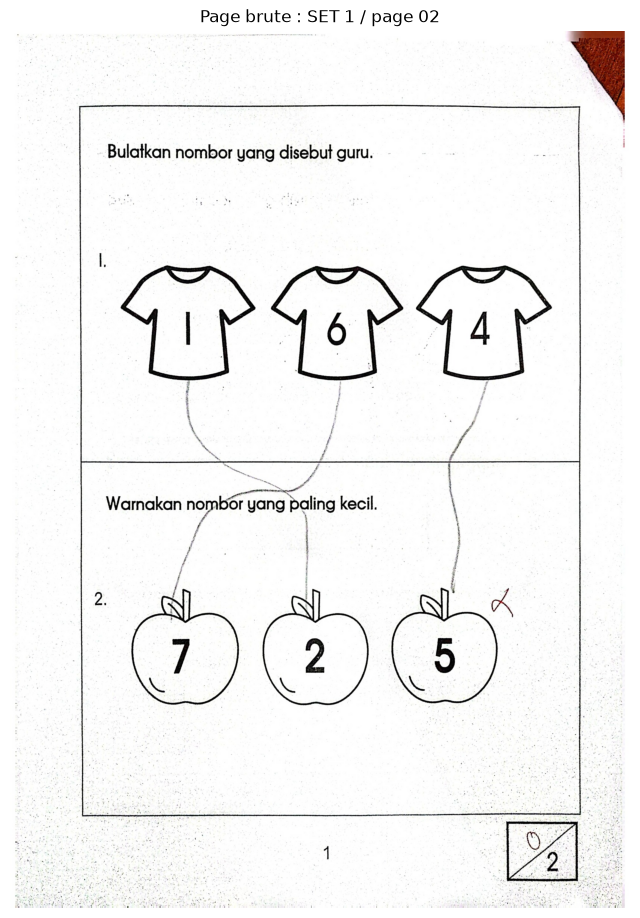

Dimensions : 1652x2338 px


In [8]:
# Preview of a raw page (before any processing)
sample_set = sets[0]
sample_path = find_page_image(sample_set, 2)  # page 2 = first page with exercises
if sample_path:
    sample_img = cv2.imread(str(sample_path))
    plt.figure(figsize=(8, 12))
    plt.imshow(cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB))
    plt.title(f"Raw page: {sample_set.name} / page 02")
    plt.axis('off')
    plt.show()
    print(f"Dimensions: {sample_img.shape[1]}x{sample_img.shape[0]} px")
else:
    print("Page 02 not found, check the file naming")

## 5. Pipeline demo on one page

We display each processing step on one page to check that everything works before running on the whole dataset.

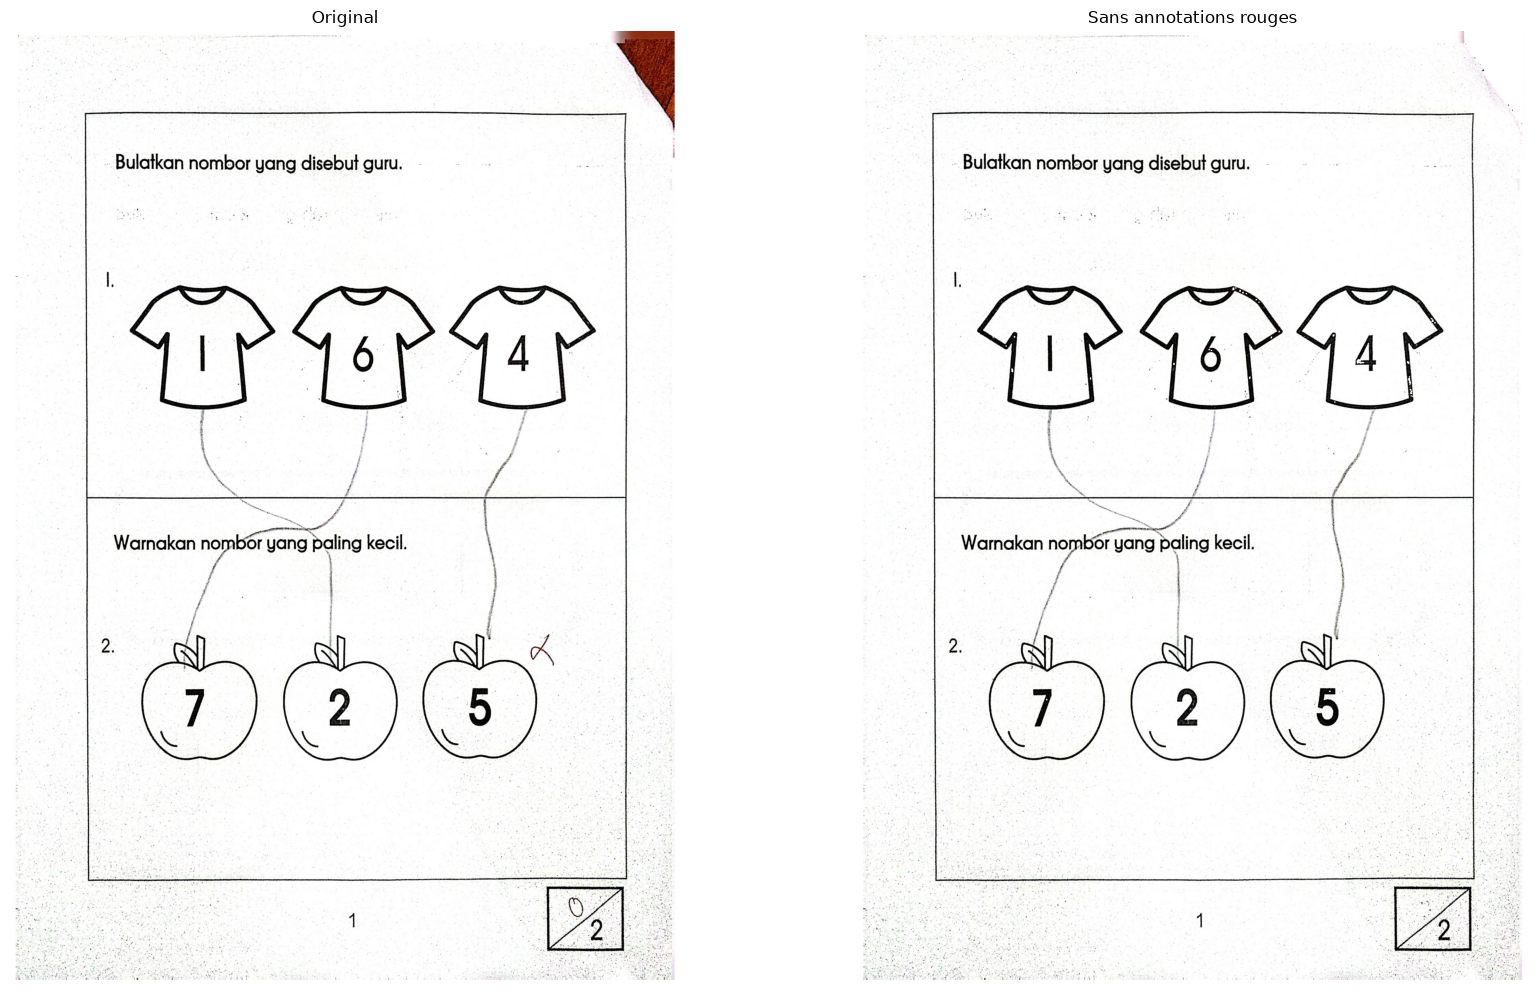

In [9]:
if sample_path:
    img = cv2.imread(str(sample_path))
    
    img_clean = remove_red_annotations(img)
    
    fig, axes = plt.subplots(1, 2, figsize=(18, 10))
    axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Original")
    axes[0].axis('off')
    
    axes[1].imshow(cv2.cvtColor(img_clean, cv2.COLOR_BGR2RGB))
    axes[1].set_title("Without red annotations")
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.show()

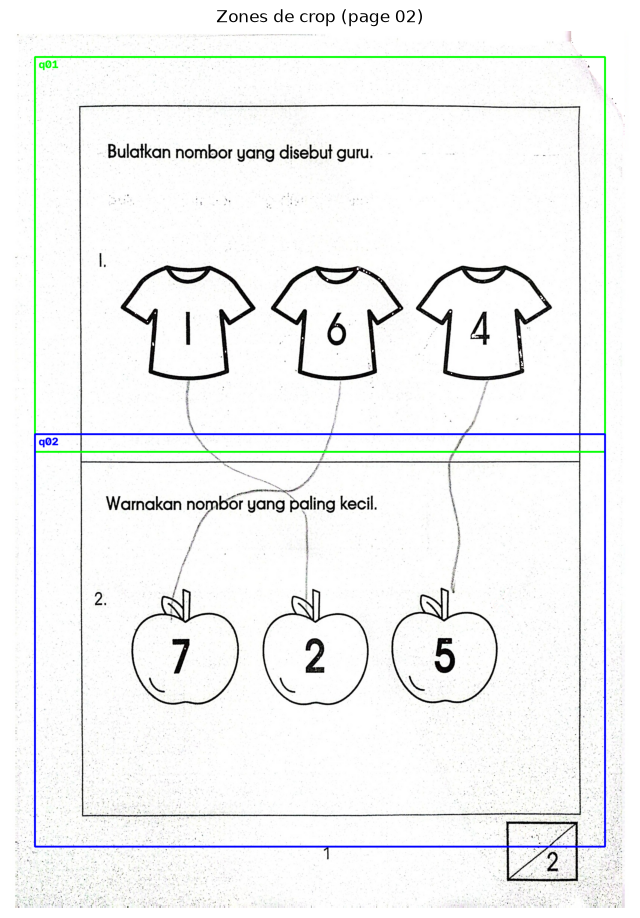

In [10]:
# Show the crop zones on the cleaned page
if sample_path:
    img_debug = img_clean.copy()
    h, w = img_debug.shape[:2]
    colors = [(0, 255, 0), (255, 0, 0), (0, 0, 255), (255, 255, 0)]
    
    page_config = CROP_CONFIG.get("02", {})
    for i, (q_name, coords) in enumerate(page_config.items()):
        y1, y2, x1, x2 = coords
        pt1 = (int(x1 * w), int(y1 * h))
        pt2 = (int(x2 * w), int(y2 * h))
        color = colors[i % len(colors)]
        cv2.rectangle(img_debug, pt1, pt2, color, 3)
        cv2.putText(img_debug, q_name, (pt1[0] + 10, pt1[1] + 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 1, color, 2)
    
    plt.figure(figsize=(8, 12))
    plt.imshow(cv2.cvtColor(img_debug, cv2.COLOR_BGR2RGB))
    plt.title("Crop zones (page 02)")
    plt.axis('off')
    plt.show()

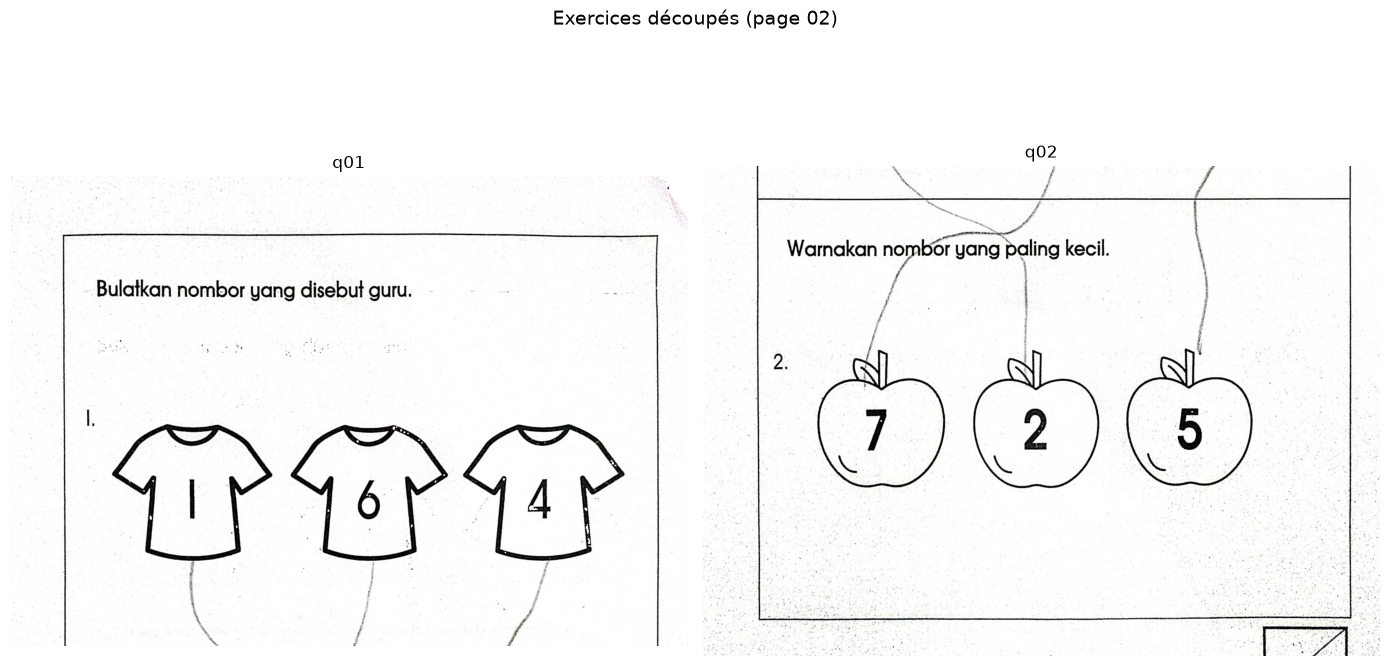

In [11]:
# Preview of the individual crops
if sample_path:
    page_config = CROP_CONFIG.get("02", {})
    fig, axes = plt.subplots(1, len(page_config), figsize=(14, 8))
    if len(page_config) == 1:
        axes = [axes]
    
    for ax, (q_name, coords) in zip(axes, page_config.items()):
        crop = crop_question(img_clean, coords)
        ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
        ax.set_title(q_name)
        ax.axis('off')
    
    plt.suptitle("Cropped exercises (page 02)", fontsize=14)
    plt.tight_layout()
    plt.show()

## 6. Running the full pipeline

We now process all SETs. For each page of each SET:
1. Red removal
2. Exercise cropping

**Output**:
- `by_exercise/q01/` ... `by_exercise/q30/`: all students for a given exercise (useful for comparison)
- `by_student/set_1/`, `by_student/set_2/`, ...: all exercises of a given student

In [12]:
# Create the output folders
by_exercise_dir = OUTPUT_DIR / "by_exercise"
by_student_dir = OUTPUT_DIR / "by_student"
verify_dir = OUTPUT_DIR / "verify"

by_exercise_dir.mkdir(parents=True, exist_ok=True)
by_student_dir.mkdir(parents=True, exist_ok=True)
verify_dir.mkdir(parents=True, exist_ok=True)

print("Output folders created")

Dossiers de sortie créés


In [13]:
# Main pipeline
stats = {"processed": 0, "skipped": 0, "empty_crops": 0}

for set_dir in sets:
    set_name = set_dir.name.lower().replace(" ", "_")
    print(f"\n{'='*50}")
    print(f"Processing {set_dir.name}...")
    
    # Student folder
    student_dir = by_student_dir / set_name
    student_dir.mkdir(parents=True, exist_ok=True)
    
    # Verification folder
    verify_set_dir = verify_dir / set_name
    verify_set_dir.mkdir(parents=True, exist_ok=True)
    
    for page_str, questions in CROP_CONFIG.items():
        page_num = int(page_str)
        img_path = find_page_image(set_dir, page_num)
        
        if img_path is None:
            print(f"  Page {page_str}: NOT FOUND")
            stats["skipped"] += 1
            continue
        
        img = cv2.imread(str(img_path))
        if img is None:
            print(f"  Page {page_str}: UNREADABLE")
            stats["skipped"] += 1
            continue
        
        print(f"  Page {page_str} ({len(questions)} exercises)...")
        
        img_clean = remove_red_annotations(img)
        
        # Cropping
        for q_name, coords in questions.items():
            crop = crop_question(img_clean, coords)
            
            if crop.size == 0:
                print(f"    {q_name}: empty crop!")
                stats["empty_crops"] += 1
                continue
            
            filename = f"{set_name}_{q_name}.jpg"
            
            # by_exercise
            exercise_dir = by_exercise_dir / q_name
            exercise_dir.mkdir(parents=True, exist_ok=True)
            cv2.imwrite(str(exercise_dir / filename), crop)
            
            # by_student
            cv2.imwrite(str(student_dir / f"{q_name}.jpg"), crop)
            
            stats["processed"] += 1
        
        # Save verification image: crop zones drawn
        img_debug = img_clean.copy()
        h, w = img_debug.shape[:2]
        colors = [(0, 255, 0), (255, 0, 0), (0, 0, 255), (255, 255, 0)]
        for i, (q_name, coords) in enumerate(questions.items()):
            y1, y2, x1, x2 = coords
            pt1 = (int(x1 * w), int(y1 * h))
            pt2 = (int(x2 * w), int(y2 * h))
            color = colors[i % len(colors)]
            cv2.rectangle(img_debug, pt1, pt2, color, 3)
            cv2.putText(img_debug, q_name, (pt1[0] + 10, pt1[1] + 30),
                        cv2.FONT_HERSHEY_SIMPLEX, 1, color, 2)
        cv2.imwrite(str(verify_set_dir / f"page_{page_str}_zones.jpg"), img_debug)

print(f"\n{'='*50}")
print(f"DONE!")
print(f"Crops generated: {stats['processed']}")
print(f"Pages skipped: {stats['skipped']}")
print(f"Empty crops: {stats['empty_crops']}")


Traitement de SET 1...
  Page 02 (2 exercices)...
  Page 03 (1 exercices)...
  Page 04 (2 exercices)...
  Page 05 (2 exercices)...
  Page 06 (2 exercices)...
  Page 07 (2 exercices)...
  Page 08 (2 exercices)...
  Page 09 (2 exercices)...
  Page 10 (2 exercices)...
  Page 11 (2 exercices)...
  Page 12 (2 exercices)...
  Page 13 (2 exercices)...
  Page 14 (2 exercices)...
  Page 15 (2 exercices)...

Traitement de SET 2...
  Page 02 (2 exercices)...
  Page 03 (1 exercices)...
  Page 04 (2 exercices)...
  Page 05 (2 exercices)...
  Page 06 (2 exercices)...
  Page 07 (2 exercices)...
  Page 08 (2 exercices)...
  Page 09 (2 exercices)...
  Page 10 (2 exercices)...
  Page 11 (2 exercices)...
  Page 12 (2 exercices)...
  Page 13 (2 exercices)...
  Page 14 (2 exercices)...
  Page 15 (2 exercices)...

Traitement de SET 3...
  Page 02 (2 exercices)...
  Page 03 (1 exercices)...
  Page 04 (2 exercices)...
  Page 05 (2 exercices)...
  Page 06 (2 exercices)...
  Page 07 (2 exercices)...
  Page 08 

## 7. Results check

We display a few crops to visually check that the zones are correct and that the red has been removed.

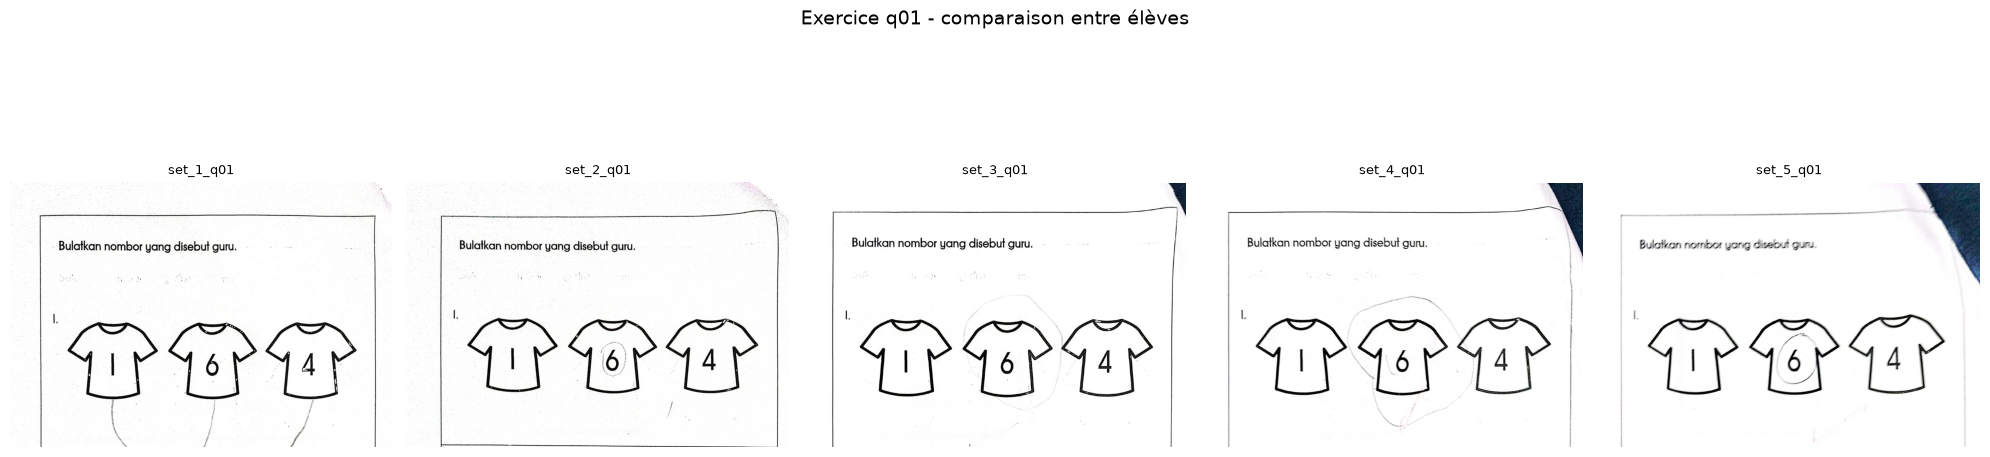

In [14]:
# Check: compare the same exercise across several students
exercise_to_check = "q01"  # change to check other exercises

exercise_path = by_exercise_dir / exercise_to_check
if exercise_path.exists():
    crops = sorted(exercise_path.glob("*.jpg"))[:5]  # first 5
    
    fig, axes = plt.subplots(1, len(crops), figsize=(20, 6))
    if len(crops) == 1:
        axes = [axes]
    
    for ax, crop_path in zip(axes, crops):
        crop_img = cv2.imread(str(crop_path))
        ax.imshow(cv2.cvtColor(crop_img, cv2.COLOR_BGR2RGB))
        ax.set_title(crop_path.stem, fontsize=9)
        ax.axis('off')
    
    plt.suptitle(f"Exercise {exercise_to_check} - comparison across students", fontsize=14)
    plt.tight_layout()
    plt.show()
else:
    print(f"Folder {exercise_to_check} not found")

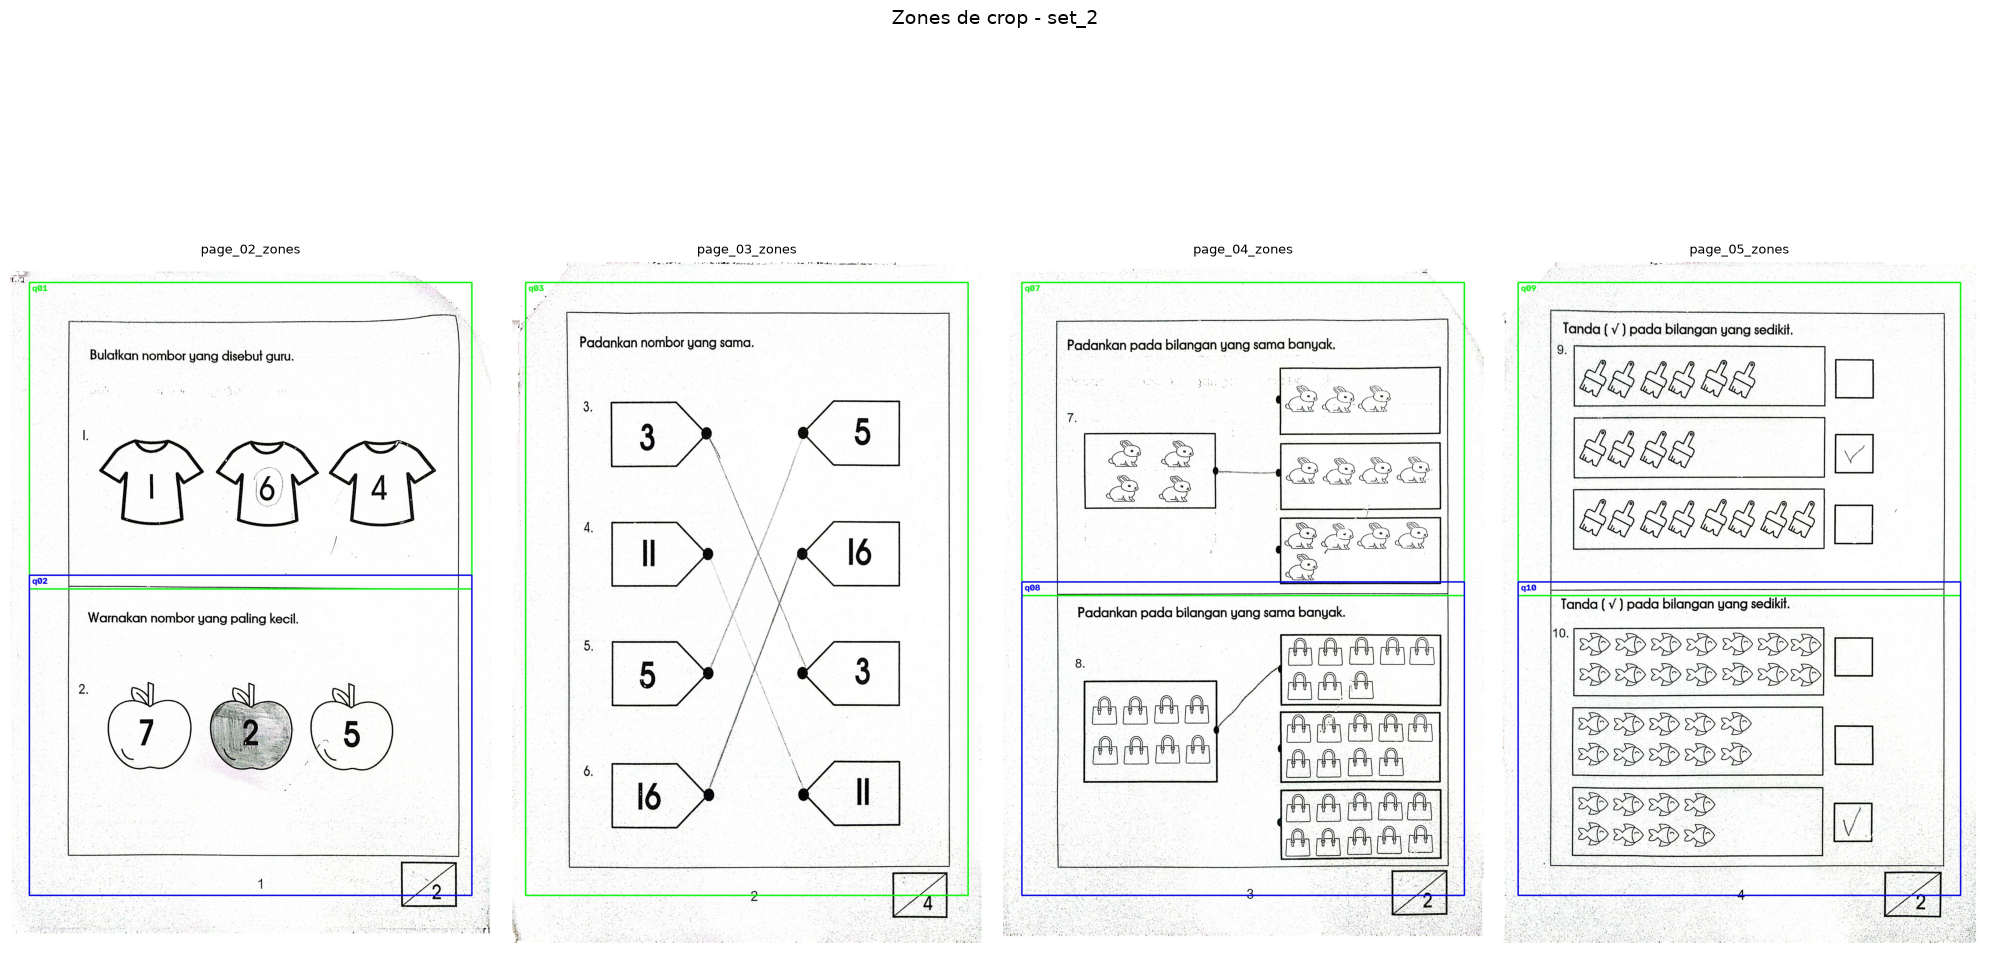

In [15]:
# Check: show the crop zones for a given SET
set_to_check = sets[1].name.lower().replace(" ", "_") if len(sets) > 1 else sets[0].name.lower().replace(" ", "_")

verify_set_path = verify_dir / set_to_check
if verify_set_path.exists():
    zone_files = sorted(verify_set_path.glob("*_zones.jpg"))[:4]
    
    fig, axes = plt.subplots(1, len(zone_files), figsize=(20, 12))
    if len(zone_files) == 1:
        axes = [axes]
    
    for ax, zf in zip(axes, zone_files):
        zone_img = cv2.imread(str(zf))
        ax.imshow(cv2.cvtColor(zone_img, cv2.COLOR_BGR2RGB))
        ax.set_title(zf.stem, fontsize=9)
        ax.axis('off')
    
    plt.suptitle(f"Crop zones - {set_to_check}", fontsize=14)
    plt.tight_layout()
    plt.show()

## 8. Dataset statistics

Summary of what was generated.

In [16]:
print("Output structure:")
print(f"  {OUTPUT_DIR}/")
print(f"  +-- by_exercise/")

for q_dir in sorted(by_exercise_dir.iterdir()):
    if q_dir.is_dir():
        count = len(list(q_dir.glob("*.jpg")))
        print(f"  |   +-- {q_dir.name}/  ({count} images)")

print(f"  +-- by_student/")
for s_dir in sorted(by_student_dir.iterdir()):
    if s_dir.is_dir():
        count = len(list(s_dir.glob("*.jpg")))
        print(f"      +-- {s_dir.name}/  ({count} exercises)")

total = sum(1 for _ in by_exercise_dir.rglob("*.jpg"))
print(f"\nTotal crops: {total}")
n_exercises = sum(len(q) for q in CROP_CONFIG.values())
print(f"Expected: {len(sets)} students x {n_exercises} exercises = {len(sets) * n_exercises}")

Structure de sortie :
  ..\data\cleaned/
  +-- by_exercise/
  |   +-- q01/  (5 images)
  |   +-- q02/  (5 images)
  |   +-- q03/  (5 images)
  |   +-- q07/  (5 images)
  |   +-- q08/  (5 images)
  |   +-- q09/  (5 images)
  |   +-- q10/  (5 images)
  |   +-- q11/  (5 images)
  |   +-- q12/  (5 images)
  |   +-- q13/  (5 images)
  |   +-- q14/  (5 images)
  |   +-- q15/  (5 images)
  |   +-- q16/  (5 images)
  |   +-- q17/  (5 images)
  |   +-- q18/  (5 images)
  |   +-- q19/  (5 images)
  |   +-- q20/  (5 images)
  |   +-- q21/  (5 images)
  |   +-- q22/  (5 images)
  |   +-- q23/  (5 images)
  |   +-- q24/  (5 images)
  |   +-- q25/  (5 images)
  |   +-- q26/  (5 images)
  |   +-- q27/  (5 images)
  |   +-- q28/  (5 images)
  |   +-- q29/  (5 images)
  |   +-- q30/  (5 images)
  +-- by_student/
      +-- set_1/  (27 exercices)
      +-- set_2/  (27 exercices)
      +-- set_3/  (27 exercices)
      +-- set_4/  (27 exercices)
      +-- set_5/  (27 exercices)

Total crops : 135
Attendu :